In [2]:
import pandas as pd

In [6]:


# Load Master dataset
master = pd.read_csv(
    "../data/cleaned/Odisha_FRA_Village_Master.csv"
)

# Load Angul dataset
angul = pd.read_csv(
    "../data/cleaned/Angul/Angul_Village_Summary.csv"
)

print("Master shape:", master.shape)
print("Angul shape:", angul.shape)

Master shape: (12464, 5)
Angul shape: (176, 5)


In [7]:
print("Master columns:")
print(master.columns.tolist())

print("\nAngul columns:")
print(angul.columns.tolist())

Master columns:
['District', 'Block', 'Gram Panchayat', 'Village', 'Beneficiary_Count']

Angul columns:
['District', 'Block', 'Gram Panchayat', 'Village', 'Beneficiary_Count']


In [8]:
# Clean text columns
for data in [master, angul]:
    data["District"] = data["District"].astype(str).str.strip().str.upper()
    data["Block"] = data["Block"].astype(str).str.strip().str.upper()
    data["Village"] = data["Village"].astype(str).str.strip().str.upper()

# Create geographic key
master["village_key"] = (
    master["District"] + "|" +
    master["Block"] + "|" +
    master["Village"]
)

angul["village_key"] = (
    angul["District"] + "|" +
    angul["Block"] + "|" +
    angul["Village"]
)

print("Master unique keys:", master["village_key"].nunique())
print("Angul unique keys:", angul["village_key"].nunique())

Master unique keys: 11366
Angul unique keys: 151


In [9]:
common_keys = set(master["village_key"]).intersection(
    set(angul["village_key"])
)

print("Common village keys:", len(common_keys))

Common village keys: 151


In [10]:
duplicate_keys = angul[
    angul["village_key"].duplicated(keep=False)
].sort_values("village_key")

print("Duplicate key rows:", len(duplicate_keys))

duplicate_keys[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count",
        "village_key"
    ]
]

Duplicate key rows: 45


,District,Block,Gram Panchayat,Village,Beneficiary_Count,village_key
11,ANGUL,ATHAMALLIK,AMBASARMUNDA,HINJAGOLA,5,ANGUL|ATHAMALLIK|HINJAGOLA
26,ANGUL,ATHAMALLIK,TAINSI,HINJAGOLA,5,ANGUL|ATHAMALLIK|HINJAGOLA
22,ANGUL,ATHAMALLIK,NAGAN,SANADUDHIANALI,10,ANGUL|ATHAMALLIK|SANADUDHIANALI
23,ANGUL,ATHAMALLIK,NAGAON,SANADUDHIANALI,12,ANGUL|ATHAMALLIK|SANADUDHIANALI
131,ANGUL,PALLAHARA,PARACHHAT,BAHADAKANI,29,ANGUL|PALLAHARA|BAHADAKANI
58,ANGUL,PALLAHARA,BATISUAN,BAHADAKANI,7,ANGUL|PALLAHARA|BAHADAKANI
48,ANGUL,PALLAHARA,BANDHABHUIN,BALIBAHAL,1,ANGUL|PALLAHARA|BALIBAHAL
126,ANGUL,PALLAHARA,NAMAPASI,BALIBAHAL,33,ANGUL|PALLAHARA|BALIBAHAL
115,ANGUL,PALLAHARA,NAGIRA,BALIBAHAL,13,ANGUL|PALLAHARA|BALIBAHAL
59,ANGUL,PALLAHARA,BATISUAN,BATISUAN,2,ANGUL|PALLAHARA|BATISUAN


In [11]:
duplicate_key_counts = (
    angul["village_key"]
    .value_counts()
)

print(
    "Number of duplicated keys:",
    (duplicate_key_counts > 1).sum()
)

print(
    duplicate_key_counts[
        duplicate_key_counts > 1
    ]
)

Number of duplicated keys: 20
village_key
ANGUL|PALLAHARA|TAMBUR              4
ANGUL|PALLAHARA|BALIBAHAL           3
ANGUL|PALLAHARA|PAUNSIA             3
ANGUL|PALLAHARA|KARADAPAL           3
ANGUL|ATHAMALLIK|HINJAGOLA          2
ANGUL|ATHAMALLIK|SANADUDHIANALI     2
ANGUL|PALLAHARA|BAHADAKANI          2
ANGUL|PALLAHARA|KANTIPASI COLONY    2
ANGUL|PALLAHARA|BISHNUPUR           2
ANGUL|PALLAHARA|NANDIJHARI          2
ANGUL|PALLAHARA|SUBARNAPALI         2
ANGUL|PALLAHARA|GANJEIMUNI          2
ANGUL|PALLAHARA|JAMBUA              2
ANGUL|PALLAHARA|RANJO               2
ANGUL|PALLAHARA|RANJANA             2
ANGUL|PALLAHARA|TIRIB               2
ANGUL|PALLAHARA|RENGALI             2
ANGUL|PALLAHARA|BATISUAN            2
ANGUL|PALLAHARA|RAJADANG            2
ANGUL|PALLAHARA|KHANATAPASI         2
Name: count, dtype: int64


In [12]:
rejected_rows = angul[
    angul["Village"].str.contains(
        "REJECTED",
        case=False,
        na=False
    )
]

print("REJECTED rows:", len(rejected_rows))

rejected_rows[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count"
    ]
]

REJECTED rows: 1


,District,Block,Gram Panchayat,Village,Beneficiary_Count
2,ANGUL,ANGUL,JAGANNATHPUR,REJECTED,1


In [13]:
print(angul["Beneficiary_Count"].describe())

count    176.000000
mean      15.869318
std       19.844826
min        1.000000
25%        3.000000
50%        9.000000
75%       22.000000
max      133.000000
Name: Beneficiary_Count, dtype: float64


In [14]:
print(
    "Zero beneficiary records:",
    (angul["Beneficiary_Count"] == 0).sum()
)

print(
    "Negative beneficiary records:",
    (angul["Beneficiary_Count"] < 0).sum()
)

Zero beneficiary records: 0
Negative beneficiary records: 0


In [15]:
# Create a more reliable geographic key
# using District + Block + Gram Panchayat + Village

for data in [master, angul]:
    data["District"] = data["District"].astype(str).str.strip().str.upper()
    data["Block"] = data["Block"].astype(str).str.strip().str.upper()
    data["Gram Panchayat"] = (
        data["Gram Panchayat"]
        .astype(str)
        .str.strip()
        .str.upper()
    )
    data["Village"] = data["Village"].astype(str).str.strip().str.upper()

master["geo_key"] = (
    master["District"] + "|" +
    master["Block"] + "|" +
    master["Gram Panchayat"] + "|" +
    master["Village"]
)

angul["geo_key"] = (
    angul["District"] + "|" +
    angul["Block"] + "|" +
    angul["Gram Panchayat"] + "|" +
    angul["Village"]
)

print("Master rows:", len(master))
print("Master unique geo keys:", master["geo_key"].nunique())

print("Angul rows:", len(angul))
print("Angul unique geo keys:", angul["geo_key"].nunique())

Master rows: 12464
Master unique geo keys: 12425
Angul rows: 176
Angul unique geo keys: 176


In [16]:
duplicate_geo = angul[
    angul["geo_key"].duplicated(keep=False)
].sort_values("geo_key")

print("Duplicate geographic keys:", len(duplicate_geo))

duplicate_geo[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count",
        "geo_key"
    ]
]

Duplicate geographic keys: 0


,District,Block,Gram Panchayat,Village,Beneficiary_Count,geo_key


In [17]:
master_duplicate_geo = master[
    master["geo_key"].duplicated(keep=False)
].sort_values("geo_key")

print("Master duplicate geographic rows:", len(master_duplicate_geo))

Master duplicate geographic rows: 77


In [18]:
common_geo_keys = set(master["geo_key"]).intersection(
    set(angul["geo_key"])
)

print("Master unique geo keys:", master["geo_key"].nunique())
print("Angul unique geo keys:", angul["geo_key"].nunique())
print("Common geo keys:", len(common_geo_keys))

Master unique geo keys: 12425
Angul unique geo keys: 176
Common geo keys: 176


In [19]:
print("Master columns:")
print(master.columns.tolist())

print("\nAngul columns:")
print(angul.columns.tolist())

Master columns:
['District', 'Block', 'Gram Panchayat', 'Village', 'Beneficiary_Count', 'village_key', 'geo_key']

Angul columns:
['District', 'Block', 'Gram Panchayat', 'Village', 'Beneficiary_Count', 'village_key', 'geo_key']


In [20]:
comparison = master[
    master["geo_key"].isin(common_geo_keys)
][
    ["geo_key", "Beneficiary_Count"]
].merge(
    angul[
        angul["geo_key"].isin(common_geo_keys)
    ][
        ["geo_key", "Beneficiary_Count"]
    ],
    on="geo_key",
    how="inner",
    suffixes=("_master", "_angul")
)

comparison.head(20)

,geo_key,Beneficiary_Count_master,Beneficiary_Count_angul
0,ANGUL|ANGUL|BADAKANTAKUL|KARABIRA,8,8
1,ANGUL|ANGUL|JAGANNATHPUR|ASANABAHAL,3,3
2,ANGUL|ANGUL|JAGANNATHPUR|REJECTED,1,1
3,ANGUL|ANGUL|JAGANNATHPUR|SALORE,8,8
4,ANGUL|ANGUL|JAGANNATHPUR|TARAVA,23,23
5,ANGUL|ANGUL|PURUNAKOTE|BHRUKUNDI,22,22
6,ANGUL|ANGUL|PURUNAKOTE|GOPALPUR,8,8
7,ANGUL|ATHAMALLIK|AMBASARMUNDA|AMSARMUNDA,1,1
8,ANGUL|ATHAMALLIK|AMBASARMUNDA|CHINTAMANIPUR,4,4
9,ANGUL|ATHAMALLIK|AMBASARMUNDA|DINABANDHUPUR,1,1


In [21]:
print(
    "Matching beneficiary counts:",
    (
        comparison["Beneficiary_Count_master"]
        ==
        comparison["Beneficiary_Count_angul"]
    ).sum()
)

print(
    "Different beneficiary counts:",
    (
        comparison["Beneficiary_Count_master"]
        !=
        comparison["Beneficiary_Count_angul"]
    ).sum()
)

Matching beneficiary counts: 176
Different beneficiary counts: 0


In [22]:
for data in [master, angul]:
    for col in ["District", "Block", "Gram Panchayat", "Village"]:
        data[col] = data[col].astype(str).str.strip().str.upper()

master["geo_key"] = (
    master["District"] + "|" +
    master["Block"] + "|" +
    master["Gram Panchayat"] + "|" +
    master["Village"]
)

angul["geo_key"] = (
    angul["District"] + "|" +
    angul["Block"] + "|" +
    angul["Gram Panchayat"] + "|" +
    angul["Village"]
)

print("Master unique geo keys:", master["geo_key"].nunique())
print("Angul unique geo keys:", angul["geo_key"].nunique())

Master unique geo keys: 12425
Angul unique geo keys: 176


In [23]:
print(
    "Master duplicate geo keys:",
    master["geo_key"].duplicated().sum()
)

print(
    "Angul duplicate geo keys:",
    angul["geo_key"].duplicated().sum()
)

Master duplicate geo keys: 39
Angul duplicate geo keys: 0


In [24]:
common_geo_keys = set(master["geo_key"]).intersection(
    set(angul["geo_key"])
)

print("Common geo keys:", len(common_geo_keys))

Common geo keys: 176


In [25]:
# Inspect duplicate geographic records in Master

master_duplicates = master[
    master["geo_key"].duplicated(keep=False)
].sort_values("geo_key")

print("Total duplicate rows:", len(master_duplicates))
print("Number of duplicated geo keys:",
      master_duplicates["geo_key"].nunique())

master_duplicates[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count",
        "geo_key"
    ]
]

Total duplicate rows: 77
Number of duplicated geo keys: 38


,District,Block,Gram Panchayat,Village,Beneficiary_Count,geo_key
7695,MAYURBHANJ,BAHALDA,GIDIGHATY,GIDIGHATY,3,MAYURBHANJ|BAHALDA|GIDIGHATY|GIDIGHATY
7710,MAYURBHANJ,BAHALDA,GIDIGHATY,GIDIGHATY,3,MAYURBHANJ|BAHALDA|GIDIGHATY|GIDIGHATY
7791,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,103,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...
7792,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,101,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...
8000,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,23,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR
...,...,...,...,...,...,...
9716,MAYURBHANJ,SARASKANA,SANKHABHANGA,SANKHABHANGA,1,MAYURBHANJ|SARASKANA|SANKHABHANGA|SANKHABHANGA
9619,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,36,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE
9904,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,26,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE
9931,MAYURBHANJ,SULIAPADA,UFALGADIA,CHANDABILA,11,MAYURBHANJ|SULIAPADA|UFALGADIA|CHANDABILA


In [26]:
# Check whether duplicate geographic keys have different beneficiary counts

duplicate_summary = (
    master_duplicates
    .groupby("geo_key")["Beneficiary_Count"]
    .agg(
        rows="count",
        unique_beneficiary_counts="nunique",
        min_beneficiary="min",
        max_beneficiary="max"
    )
    .reset_index()
)

print("Duplicate geo keys:", len(duplicate_summary))

print("\nKeys with DIFFERENT beneficiary counts:")
conflicting_duplicates = duplicate_summary[
    duplicate_summary["unique_beneficiary_counts"] > 1
]

print("Number of conflicting keys:", len(conflicting_duplicates))

conflicting_duplicates

Duplicate geo keys: 38

Keys with DIFFERENT beneficiary counts:
Number of conflicting keys: 35


,geo_key,rows,unique_beneficiary_counts,min_beneficiary,max_beneficiary
1,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...,2,2,101,103
2,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR,2,2,6,23
3,MAYURBHANJ|BISOI|ASANA|ARJUNBILA,2,2,1,17
4,MAYURBHANJ|BISOI|BANEIKALA|GUNDURIA,2,2,1,24
5,MAYURBHANJ|BISOI|BAUTIBEDA|OSHADALA,2,2,18,23
6,MAYURBHANJ|BISOI|BAUTIBEDA|PURUNA BALICHUA,2,2,3,44
7,MAYURBHANJ|BISOI|BISOI|SAGJODI,2,2,6,24
8,MAYURBHANJ|BISOI|KHADAMBEDA|ARGALBINDHA,3,2,1,49
9,MAYURBHANJ|BISOI|KHADAMBEDA|KITABEDA,2,2,27,28
10,MAYURBHANJ|BISOI|KHADAMBEDA|PUNDIDA,2,2,3,36


In [27]:
# Show all rows where the same geo_key has different beneficiary counts

conflicting_keys = set(
    conflicting_duplicates["geo_key"]
)

conflicting_rows = master[
    master["geo_key"].isin(conflicting_keys)
].sort_values("geo_key")

print("Conflicting rows:", len(conflicting_rows))

conflicting_rows[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count",
        "geo_key"
    ]
]

Conflicting rows: 71


,District,Block,Gram Panchayat,Village,Beneficiary_Count,geo_key
7791,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,103,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...
7792,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,101,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...
8000,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,23,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR
8001,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,6,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR
8166,MAYURBHANJ,BISOI,ASANA,ARJUNBILA,17,MAYURBHANJ|BISOI|ASANA|ARJUNBILA
...,...,...,...,...,...,...
9716,MAYURBHANJ,SARASKANA,SANKHABHANGA,SANKHABHANGA,1,MAYURBHANJ|SARASKANA|SANKHABHANGA|SANKHABHANGA
9619,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,36,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE
9904,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,26,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE
9951,MAYURBHANJ,SULIAPADA,UFALGADIA,CHANDABILA,1,MAYURBHANJ|SULIAPADA|UFALGADIA|CHANDABILA


In [28]:
# Inspect whether conflicting rows differ only in Beneficiary_Count

conflict_check = (
    conflicting_rows
    .groupby("geo_key")
    .agg(
        rows=("geo_key", "size"),
        beneficiary_values=("Beneficiary_Count", lambda x: sorted(x.tolist())),
        district=("District", "first"),
        block=("Block", "first"),
        gram_panchayat=("Gram Panchayat", "first"),
        village=("Village", "first")
    )
    .reset_index()
)

conflict_check

,geo_key,rows,beneficiary_values,district,block,gram_panchayat,village
0,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...,2,"[101, 103]",MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA
1,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR,2,"[6, 23]",MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR
2,MAYURBHANJ|BISOI|ASANA|ARJUNBILA,2,"[1, 17]",MAYURBHANJ,BISOI,ASANA,ARJUNBILA
3,MAYURBHANJ|BISOI|BANEIKALA|GUNDURIA,2,"[1, 24]",MAYURBHANJ,BISOI,BANEIKALA,GUNDURIA
4,MAYURBHANJ|BISOI|BAUTIBEDA|OSHADALA,2,"[18, 23]",MAYURBHANJ,BISOI,BAUTIBEDA,OSHADALA
5,MAYURBHANJ|BISOI|BAUTIBEDA|PURUNA BALICHUA,2,"[3, 44]",MAYURBHANJ,BISOI,BAUTIBEDA,PURUNA BALICHUA
6,MAYURBHANJ|BISOI|BISOI|SAGJODI,2,"[6, 24]",MAYURBHANJ,BISOI,BISOI,SAGJODI
7,MAYURBHANJ|BISOI|KHADAMBEDA|ARGALBINDHA,3,"[1, 1, 49]",MAYURBHANJ,BISOI,KHADAMBEDA,ARGALBINDHA
8,MAYURBHANJ|BISOI|KHADAMBEDA|KITABEDA,2,"[27, 28]",MAYURBHANJ,BISOI,KHADAMBEDA,KITABEDA
9,MAYURBHANJ|BISOI|KHADAMBEDA|PUNDIDA,2,"[3, 36]",MAYURBHANJ,BISOI,KHADAMBEDA,PUNDIDA


In [30]:
# Create a clean summary of conflicting geographic keys

conflict_check = (
    conflicting_rows
    .groupby("geo_key")
    .agg(
        rows=("geo_key", "size"),
        unique_beneficiary_counts=("Beneficiary_Count", "nunique"),
        min_beneficiary=("Beneficiary_Count", "min"),
        max_beneficiary=("Beneficiary_Count", "max")
    )
    .reset_index()
)

print("Total conflicting geographic keys:", len(conflict_check))

conflict_check.sort_values(
    ["max_beneficiary", "min_beneficiary"],
    ascending=False
)

Total conflicting geographic keys: 35


,geo_key,rows,unique_beneficiary_counts,min_beneficiary,max_beneficiary
32,MAYURBHANJ|SARASKANA|SANKHABHANGA|SANKHABHANGA,2,2,1,131
0,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...,2,2,101,103
29,MAYURBHANJ|RAIRANGPUR|PURUNAPANI|MURGAGHUTU,2,2,2,57
7,MAYURBHANJ|BISOI|KHADAMBEDA|ARGALBINDHA,3,2,1,49
5,MAYURBHANJ|BISOI|BAUTIBEDA|PURUNA BALICHUA,2,2,3,44
13,MAYURBHANJ|KARANJIA|DUDHIANI|SANRAMCHANDRAPUR,2,2,3,42
25,MAYURBHANJ|RAIRANGPUR|KULEISILA|CHATRAMANDAL,2,2,9,41
33,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE,2,2,26,36
9,MAYURBHANJ|BISOI|KHADAMBEDA|PUNDIDA,2,2,3,36
18,MAYURBHANJ|KUSUMI|JHIPABANDH|PECHADAR,2,2,1,34


In [31]:
# Show all rows belonging to the 35 conflicting geographic keys

conflicting_keys = set(conflict_check["geo_key"])

conflicting_rows_full = (
    master[master["geo_key"].isin(conflicting_keys)]
    .sort_values(["District", "Block", "Gram Panchayat", "Village", "Beneficiary_Count"])
)

print("Total conflicting rows:", len(conflicting_rows_full))

conflicting_rows_full[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count",
        "geo_key"
    ]
]

Total conflicting rows: 71


,District,Block,Gram Panchayat,Village,Beneficiary_Count,geo_key
7792,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,101,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...
7791,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,103,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...
8001,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,6,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR
8000,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,23,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR
8181,MAYURBHANJ,BISOI,ASANA,ARJUNBILA,1,MAYURBHANJ|BISOI|ASANA|ARJUNBILA
...,...,...,...,...,...,...
9715,MAYURBHANJ,SARASKANA,SANKHABHANGA,SANKHABHANGA,131,MAYURBHANJ|SARASKANA|SANKHABHANGA|SANKHABHANGA
9904,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,26,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE
9619,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,36,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE
9951,MAYURBHANJ,SULIAPADA,UFALGADIA,CHANDABILA,1,MAYURBHANJ|SULIAPADA|UFALGADIA|CHANDABILA


In [32]:
# Check exact duplicate records

exact_duplicate_rows = master[
    master.duplicated(
        subset=[
            "District",
            "Block",
            "Gram Panchayat",
            "Village",
            "Beneficiary_Count"
        ],
        keep=False
    )
].sort_values("geo_key")

print("Exact duplicate rows:", len(exact_duplicate_rows))

exact_duplicate_rows[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count",
        "geo_key"
    ]
]

Exact duplicate rows: 8


,District,Block,Gram Panchayat,Village,Beneficiary_Count,geo_key
7695,MAYURBHANJ,BAHALDA,GIDIGHATY,GIDIGHATY,3,MAYURBHANJ|BAHALDA|GIDIGHATY|GIDIGHATY
7710,MAYURBHANJ,BAHALDA,GIDIGHATY,GIDIGHATY,3,MAYURBHANJ|BAHALDA|GIDIGHATY|GIDIGHATY
8262,MAYURBHANJ,BISOI,KHADAMBEDA,ARGALBINDHA,1,MAYURBHANJ|BISOI|KHADAMBEDA|ARGALBINDHA
8307,MAYURBHANJ,BISOI,KHADAMBEDA,ARGALBINDHA,1,MAYURBHANJ|BISOI|KHADAMBEDA|ARGALBINDHA
9296,MAYURBHANJ,NAME OF THE BLOCK,NAME OF THE G.P.,NAME OF THE REVENUE VILAGE,1,MAYURBHANJ|NAME OF THE BLOCK|NAME OF THE G.P.|...
9297,MAYURBHANJ,NAME OF THE BLOCK,NAME OF THE G.P.,NAME OF THE REVENUE VILAGE,1,MAYURBHANJ|NAME OF THE BLOCK|NAME OF THE G.P.|...
9335,MAYURBHANJ,RAIRANGPUR,KULEISILA,BETPANI,4,MAYURBHANJ|RAIRANGPUR|KULEISILA|BETPANI
9396,MAYURBHANJ,RAIRANGPUR,KULEISILA,BETPANI,4,MAYURBHANJ|RAIRANGPUR|KULEISILA|BETPANI


In [33]:
# Count exact duplicate groups

exact_duplicate_groups = (
    exact_duplicate_rows
    .groupby("geo_key")
    .size()
    .reset_index(name="duplicate_rows")
    .sort_values("duplicate_rows", ascending=False)
)

print("Number of exact duplicate groups:", len(exact_duplicate_groups))

exact_duplicate_groups

Number of exact duplicate groups: 4


,geo_key,duplicate_rows
0,MAYURBHANJ|BAHALDA|GIDIGHATY|GIDIGHATY,2
1,MAYURBHANJ|BISOI|KHADAMBEDA|ARGALBINDHA,2
2,MAYURBHANJ|NAME OF THE BLOCK|NAME OF THE G.P.|...,2
3,MAYURBHANJ|RAIRANGPUR|KULEISILA|BETPANI,2


In [34]:
# Remove exact duplicate records
master_clean = master.drop_duplicates(
    subset=[
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count"
    ],
    keep="first"
).copy()

print("Original master rows:", len(master))
print("Clean master rows:", len(master_clean))
print("Rows removed:", len(master) - len(master_clean))

print("\nDuplicate rows after cleaning:")
print(
    master_clean.duplicated(
        subset=[
            "District",
            "Block",
            "Gram Panchayat",
            "Village",
            "Beneficiary_Count"
        ]
    ).sum()
)

Original master rows: 12464
Clean master rows: 12460
Rows removed: 4

Duplicate rows after cleaning:
0


In [35]:
# Check conflicting geographic records after removing exact duplicates

conflicting_groups = (
    master_clean
    .groupby("geo_key")["Beneficiary_Count"]
    .agg(
        rows="size",
        unique_beneficiary_counts="nunique",
        min_beneficiary="min",
        max_beneficiary="max"
    )
    .reset_index()
)

conflicting_groups = conflicting_groups[
    conflicting_groups["unique_beneficiary_counts"] > 1
].sort_values(
    "max_beneficiary",
    ascending=False
)

print("Conflicting geographic keys:", len(conflicting_groups))

conflicting_groups

Conflicting geographic keys: 35


,geo_key,rows,unique_beneficiary_counts,min_beneficiary,max_beneficiary
9673,MAYURBHANJ|SARASKANA|SANKHABHANGA|SANKHABHANGA,2,2,1,131
7774,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...,2,2,101,103
9359,MAYURBHANJ|RAIRANGPUR|PURUNAPANI|MURGAGHUTU,2,2,2,57
8237,MAYURBHANJ|BISOI|KHADAMBEDA|ARGALBINDHA,2,2,1,49
8219,MAYURBHANJ|BISOI|BAUTIBEDA|PURUNA BALICHUA,2,2,3,44
8793,MAYURBHANJ|KARANJIA|DUDHIANI|SANRAMCHANDRAPUR,2,2,3,42
9347,MAYURBHANJ|RAIRANGPUR|KULEISILA|CHATRAMANDAL,2,2,9,41
9871,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE,2,2,26,36
8251,MAYURBHANJ|BISOI|KHADAMBEDA|PUNDIDA,2,2,3,36
9127,MAYURBHANJ|KUSUMI|JHIPABANDH|PECHADAR,2,2,1,34


In [36]:
# Show all records for the 35 conflicting geographic keys

conflicting_keys = set(conflicting_groups["geo_key"])

conflicting_records = (
    master_clean[
        master_clean["geo_key"].isin(conflicting_keys)
    ]
    .sort_values(
        ["District", "Block", "Gram Panchayat", "Village", "Beneficiary_Count"]
    )
)

print("Total conflicting records:", len(conflicting_records))

conflicting_records[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count",
        "geo_key"
    ]
]

Total conflicting records: 70


,District,Block,Gram Panchayat,Village,Beneficiary_Count,geo_key
7792,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,101,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...
7791,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,103,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...
8001,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,6,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR
8000,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,23,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR
8181,MAYURBHANJ,BISOI,ASANA,ARJUNBILA,1,MAYURBHANJ|BISOI|ASANA|ARJUNBILA
...,...,...,...,...,...,...
9715,MAYURBHANJ,SARASKANA,SANKHABHANGA,SANKHABHANGA,131,MAYURBHANJ|SARASKANA|SANKHABHANGA|SANKHABHANGA
9904,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,26,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE
9619,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,36,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE
9951,MAYURBHANJ,SULIAPADA,UFALGADIA,CHANDABILA,1,MAYURBHANJ|SULIAPADA|UFALGADIA|CHANDABILA


In [37]:
# Compact conflict report

conflict_report = (
    master_clean[
        master_clean["geo_key"].isin(conflicting_keys)
    ]
    .groupby("geo_key")
    .agg(
        rows=("Beneficiary_Count", "size"),
        beneficiary_values=("Beneficiary_Count", lambda x: sorted(x.tolist())),
        district=("District", "first"),
        block=("Block", "first"),
        gram_panchayat=("Gram Panchayat", "first"),
        village=("Village", "first")
    )
    .reset_index()
)

conflict_report = conflict_report.sort_values(
    ["district", "block", "gram_panchayat", "village"]
)

print("Total conflicting locations:", len(conflict_report))

conflict_report[
    [
        "district",
        "block",
        "gram_panchayat",
        "village",
        "rows",
        "beneficiary_values"
    ]
]

Total conflicting locations: 35


,district,block,gram_panchayat,village,rows,beneficiary_values
0,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,2,"[101, 103]"
1,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,2,"[6, 23]"
2,MAYURBHANJ,BISOI,ASANA,ARJUNBILA,2,"[1, 17]"
3,MAYURBHANJ,BISOI,BANEIKALA,GUNDURIA,2,"[1, 24]"
4,MAYURBHANJ,BISOI,BAUTIBEDA,OSHADALA,2,"[18, 23]"
5,MAYURBHANJ,BISOI,BAUTIBEDA,PURUNA BALICHUA,2,"[3, 44]"
6,MAYURBHANJ,BISOI,BISOI,SAGJODI,2,"[6, 24]"
7,MAYURBHANJ,BISOI,KHADAMBEDA,ARGALBINDHA,2,"[1, 49]"
8,MAYURBHANJ,BISOI,KHADAMBEDA,KITABEDA,2,"[27, 28]"
9,MAYURBHANJ,BISOI,KHADAMBEDA,PUNDIDA,2,"[3, 36]"


In [38]:
# Flag geographic records having conflicting beneficiary counts

conflict_key_set = set(conflicting_groups["geo_key"])

master_clean["beneficiary_conflict"] = (
    master_clean["geo_key"].isin(conflict_key_set)
)

print("Total rows in clean master:", len(master_clean))
print(
    "Rows with beneficiary conflicts:",
    master_clean["beneficiary_conflict"].sum()
)
print(
    "Rows without beneficiary conflicts:",
    (~master_clean["beneficiary_conflict"]).sum()
)

Total rows in clean master: 12460
Rows with beneficiary conflicts: 70
Rows without beneficiary conflicts: 12390


In [39]:
# Create a separate report for beneficiary count conflicts

conflict_records = (
    master_clean[
        master_clean["beneficiary_conflict"]
    ]
    .sort_values(
        ["District", "Block", "Gram Panchayat", "Village", "Beneficiary_Count"]
    )
    .copy()
)

print("Conflict records:", len(conflict_records))

conflict_records[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count",
        "geo_key",
        "beneficiary_conflict"
    ]
]

Conflict records: 70


,District,Block,Gram Panchayat,Village,Beneficiary_Count,geo_key,beneficiary_conflict
7792,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,101,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...,True
7791,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,103,MAYURBHANJ|BANGIRIPOSI|KUMBHARA MUNDAKATA|KUMB...,True
8001,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,6,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR,True
8000,MAYURBHANJ,BETNOTI,BAISINGA,BAD DAMDORPUR,23,MAYURBHANJ|BETNOTI|BAISINGA|BAD DAMDORPUR,True
8181,MAYURBHANJ,BISOI,ASANA,ARJUNBILA,1,MAYURBHANJ|BISOI|ASANA|ARJUNBILA,True
...,...,...,...,...,...,...,...
9715,MAYURBHANJ,SARASKANA,SANKHABHANGA,SANKHABHANGA,131,MAYURBHANJ|SARASKANA|SANKHABHANGA|SANKHABHANGA,True
9904,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,26,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE,True
9619,MAYURBHANJ,SULIAPADA,KANTISAHI,DHANSOLE,36,MAYURBHANJ|SULIAPADA|KANTISAHI|DHANSOLE,True
9951,MAYURBHANJ,SULIAPADA,UFALGADIA,CHANDABILA,1,MAYURBHANJ|SULIAPADA|UFALGADIA|CHANDABILA,True


In [40]:
# Create final clean master dataset
# Keep conflicting records, but flag them for further analysis

final_master = master_clean.copy()

print("Final master rows:", len(final_master))
print("Final master columns:", len(final_master.columns))

print("\nConflict summary:")
print(final_master["beneficiary_conflict"].value_counts())

print("\nFinal dataset preview:")
final_master.head()

Final master rows: 12460
Final master columns: 8

Conflict summary:
beneficiary_conflict
False    12390
True        70
Name: count, dtype: int64

Final dataset preview:


,District,Block,Gram Panchayat,Village,Beneficiary_Count,village_key,geo_key,beneficiary_conflict
0,ANGUL,ANGUL,BADAKANTAKUL,KARABIRA,8,ANGUL|ANGUL|KARABIRA,ANGUL|ANGUL|BADAKANTAKUL|KARABIRA,False
1,ANGUL,ANGUL,JAGANNATHPUR,ASANABAHAL,3,ANGUL|ANGUL|ASANABAHAL,ANGUL|ANGUL|JAGANNATHPUR|ASANABAHAL,False
2,ANGUL,ANGUL,JAGANNATHPUR,REJECTED,1,ANGUL|ANGUL|REJECTED,ANGUL|ANGUL|JAGANNATHPUR|REJECTED,False
3,ANGUL,ANGUL,JAGANNATHPUR,SALORE,8,ANGUL|ANGUL|SALORE,ANGUL|ANGUL|JAGANNATHPUR|SALORE,False
4,ANGUL,ANGUL,JAGANNATHPUR,TARAVA,23,ANGUL|ANGUL|TARAVA,ANGUL|ANGUL|JAGANNATHPUR|TARAVA,False


In [41]:
# Save the final cleaned master dataset

output_path = "../data/cleaned/Odisha_FRA_Village_Master_Cleaned.csv"

final_master.to_csv(output_path, index=False)

print("Final cleaned dataset saved successfully.")
print("File:", output_path)
print("Rows saved:", len(final_master))
print("Columns saved:", len(final_master.columns))

Final cleaned dataset saved successfully.
File: ../data/cleaned/Odisha_FRA_Village_Master_Cleaned.csv
Rows saved: 12460
Columns saved: 8


In [42]:
# Save conflict report from the same analysis notebook

conflict_output_path = "../data/cleaned/FRA_Beneficiary_Conflict_Report.csv"

conflicting_rows.to_csv(conflict_output_path, index=False)

print("Conflict report saved successfully.")
print("File:", conflict_output_path)
print("Rows saved:", len(conflicting_rows))
print("Columns saved:", len(conflicting_rows.columns))

Conflict report saved successfully.
File: ../data/cleaned/FRA_Beneficiary_Conflict_Report.csv
Rows saved: 71
Columns saved: 7


In [43]:
# Final validation

print("Final dataset validation")
print("------------------------")

print("Rows:", len(final_master))
print("Columns:", len(final_master.columns))

print("\nMissing values:")
print(final_master.isnull().sum())

print("\nDuplicate rows:")
print(
    final_master.duplicated(
        subset=[
            "District",
            "Block",
            "Gram Panchayat",
            "Village",
            "Beneficiary_Count"
        ]
    ).sum()
)

print("\nBeneficiary count statistics:")
print(final_master["Beneficiary_Count"].describe())

Final dataset validation
------------------------
Rows: 12460
Columns: 8

Missing values:
District                0
Block                   0
Gram Panchayat          0
Village                 0
Beneficiary_Count       0
village_key             0
geo_key                 0
beneficiary_conflict    0
dtype: int64

Duplicate rows:
0

Beneficiary count statistics:
count    12460.000000
mean        21.990610
std         28.333568
min          1.000000
25%          5.000000
50%         13.000000
75%         28.000000
max        761.000000
Name: Beneficiary_Count, dtype: float64


In [44]:
# Final Part 2 Summary

print("=" * 50)
print("ODISHA FRA - ADDITIONAL DATA ANALYSIS SUMMARY")
print("=" * 50)

print("\nOriginal master rows:", len(master))
print("Final cleaned rows:", len(final_master))
print("Rows removed:", len(master) - len(final_master))

print("\nFinal columns:", len(final_master.columns))
print("Missing values:", final_master.isnull().sum().sum())

print("\nExact duplicate rows after cleaning:",
      final_master.duplicated(
          subset=[
              "District",
              "Block",
              "Gram Panchayat",
              "Village",
              "Beneficiary_Count"
          ]
      ).sum())

print("\nConflicting records:", final_master["beneficiary_conflict"].sum())

print("\nFinal dataset status: READY")
print("=" * 50)

ODISHA FRA - ADDITIONAL DATA ANALYSIS SUMMARY

Original master rows: 12464
Final cleaned rows: 12460
Rows removed: 4

Final columns: 8
Missing values: 0

Exact duplicate rows after cleaning: 0

Conflicting records: 70

Final dataset status: READY


In [45]:
# Inspect final dataset before feature engineering

print("Final dataset columns:")
print(final_master.columns.tolist())

print("\nData types:")
print(final_master.dtypes)

print("\nFirst 5 rows:")
display(final_master.head())

Final dataset columns:
['District', 'Block', 'Gram Panchayat', 'Village', 'Beneficiary_Count', 'village_key', 'geo_key', 'beneficiary_conflict']

Data types:
District                object
Block                   object
Gram Panchayat          object
Village                 object
Beneficiary_Count        int64
village_key             object
geo_key                 object
beneficiary_conflict      bool
dtype: object

First 5 rows:


,District,Block,Gram Panchayat,Village,Beneficiary_Count,village_key,geo_key,beneficiary_conflict
0,ANGUL,ANGUL,BADAKANTAKUL,KARABIRA,8,ANGUL|ANGUL|KARABIRA,ANGUL|ANGUL|BADAKANTAKUL|KARABIRA,False
1,ANGUL,ANGUL,JAGANNATHPUR,ASANABAHAL,3,ANGUL|ANGUL|ASANABAHAL,ANGUL|ANGUL|JAGANNATHPUR|ASANABAHAL,False
2,ANGUL,ANGUL,JAGANNATHPUR,REJECTED,1,ANGUL|ANGUL|REJECTED,ANGUL|ANGUL|JAGANNATHPUR|REJECTED,False
3,ANGUL,ANGUL,JAGANNATHPUR,SALORE,8,ANGUL|ANGUL|SALORE,ANGUL|ANGUL|JAGANNATHPUR|SALORE,False
4,ANGUL,ANGUL,JAGANNATHPUR,TARAVA,23,ANGUL|ANGUL|TARAVA,ANGUL|ANGUL|JAGANNATHPUR|TARAVA,False


In [46]:
# Feature Engineering

feature_data = final_master.copy()

# 1. Log-transformed beneficiary count
feature_data["beneficiary_log"] = (
    feature_data["Beneficiary_Count"].apply(lambda x: __import__("math").log1p(x))
)

# 2. Number of villages in each Block
feature_data["block_village_count"] = (
    feature_data.groupby("Block")["Village"].transform("nunique")
)

# 3. Number of villages in each Gram Panchayat
feature_data["gp_village_count"] = (
    feature_data.groupby(["Block", "Gram Panchayat"])["Village"]
    .transform("nunique")
)

# 4. Number of villages in each District
feature_data["district_village_count"] = (
    feature_data.groupby("District")["Village"].transform("nunique")
)

# 5. Beneficiary count relative to villages in the Gram Panchayat
feature_data["beneficiary_per_gp_village"] = (
    feature_data["Beneficiary_Count"] /
    feature_data["gp_village_count"]
)

# 6. Conflict indicator as numeric feature
feature_data["conflict_flag"] = (
    feature_data["beneficiary_conflict"].astype(int)
)

print("Feature engineering completed.")
print("Original columns:", len(final_master.columns))
print("New columns:", len(feature_data.columns))

print("\nNew features:")
print([
    "beneficiary_log",
    "block_village_count",
    "gp_village_count",
    "district_village_count",
    "beneficiary_per_gp_village",
    "conflict_flag"
])

display(feature_data.head())

Feature engineering completed.
Original columns: 8
New columns: 14

New features:
['beneficiary_log', 'block_village_count', 'gp_village_count', 'district_village_count', 'beneficiary_per_gp_village', 'conflict_flag']


,District,Block,Gram Panchayat,Village,Beneficiary_Count,village_key,geo_key,beneficiary_conflict,beneficiary_log,block_village_count,gp_village_count,district_village_count,beneficiary_per_gp_village,conflict_flag
0,ANGUL,ANGUL,BADAKANTAKUL,KARABIRA,8,ANGUL|ANGUL|KARABIRA,ANGUL|ANGUL|BADAKANTAKUL|KARABIRA,False,2.197225,7,1,150,8.00,0
1,ANGUL,ANGUL,JAGANNATHPUR,ASANABAHAL,3,ANGUL|ANGUL|ASANABAHAL,ANGUL|ANGUL|JAGANNATHPUR|ASANABAHAL,False,1.386294,7,4,150,0.75,0
2,ANGUL,ANGUL,JAGANNATHPUR,REJECTED,1,ANGUL|ANGUL|REJECTED,ANGUL|ANGUL|JAGANNATHPUR|REJECTED,False,0.693147,7,4,150,0.25,0
3,ANGUL,ANGUL,JAGANNATHPUR,SALORE,8,ANGUL|ANGUL|SALORE,ANGUL|ANGUL|JAGANNATHPUR|SALORE,False,2.197225,7,4,150,2.00,0
4,ANGUL,ANGUL,JAGANNATHPUR,TARAVA,23,ANGUL|ANGUL|TARAVA,ANGUL|ANGUL|JAGANNATHPUR|TARAVA,False,3.178054,7,4,150,5.75,0


In [47]:
# Exploratory Data Analysis (EDA)

print("EDA - Basic Statistics")
print("=" * 50)

print("\nBeneficiary Count:")
print(feature_data["Beneficiary_Count"].describe())

print("\nConflict Flag:")
print(feature_data["conflict_flag"].value_counts())

print("\nTop 10 Districts by Village Count:")
print(
    feature_data.groupby("District")["Village"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Villages by Beneficiary Count:")
print(
    feature_data[
        ["District", "Block", "Gram Panchayat", "Village", "Beneficiary_Count"]
    ]
    .sort_values("Beneficiary_Count", ascending=False)
    .head(10)
)

EDA - Basic Statistics

Beneficiary Count:
count    12460.000000
mean        21.990610
std         28.333568
min          1.000000
25%          5.000000
50%         13.000000
75%         28.000000
max        761.000000
Name: Beneficiary_Count, dtype: float64

Conflict Flag:
conflict_flag
0    12390
1       70
Name: count, dtype: int64

Top 10 Districts by Village Count:
District
MAYURBHANJ    1927
KEONJHAR      1540
KORAPUT       1146
MALKANGIRI    1085
RAYAGADA       971
KALAHANDI      690
SAMBALPUR      663
GANJAM         368
DEOGARH        259
NUAPADA        215
Name: Village, dtype: int64

Top 10 Villages by Beneficiary Count:
         District              Block              Gram Panchayat  \
7486   MALKANGIRI  NAME OF THE BLOCK       NAME OF THE PANCHAYAT   
11469    RAYAGADA  NAME OF THE BLOCK  NAME OF THE GRAM PANCHAYAT   
5649      KORAPUT  NAME OF THE BLOCK             NAME OF THE G.P   
2075    JHARUGUDA            LAIKERA                   KHUNTAMAL   
277      BALASORE    

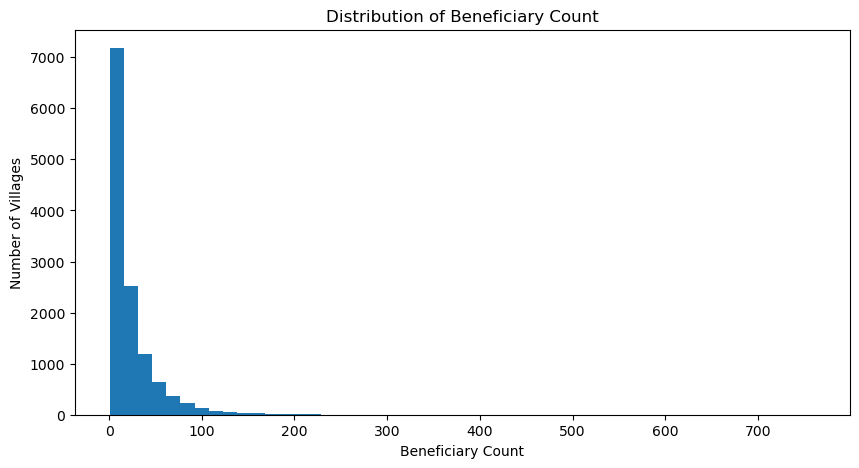

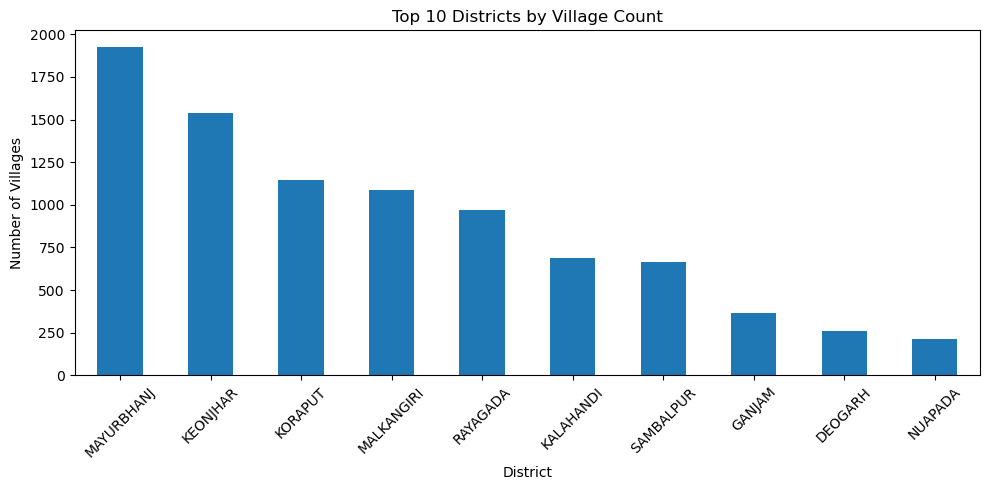

In [48]:
# EDA Visualizations

import matplotlib.pyplot as plt

# 1. Distribution of Beneficiary Count
plt.figure(figsize=(10, 5))
plt.hist(feature_data["Beneficiary_Count"], bins=50)
plt.xlabel("Beneficiary Count")
plt.ylabel("Number of Villages")
plt.title("Distribution of Beneficiary Count")
plt.show()


# 2. Top 10 Districts by Village Count
district_counts = (
    feature_data.groupby("District")["Village"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
district_counts.plot(kind="bar")
plt.xlabel("District")
plt.ylabel("Number of Villages")
plt.title("Top 10 Districts by Village Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [49]:
# Monitoring Priority Score

import numpy as np

priority_data = feature_data.copy()

# Normalize important features to 0-1
priority_data["beneficiary_score"] = (
    priority_data["beneficiary_log"] /
    priority_data["beneficiary_log"].max()
)

priority_data["beneficiary_density_score"] = (
    priority_data["beneficiary_per_gp_village"] /
    priority_data["beneficiary_per_gp_village"].max()
)

priority_data["conflict_score"] = priority_data["conflict_flag"]

# Transparent weighted priority score
priority_data["priority_score"] = (
    0.50 * priority_data["beneficiary_score"] +
    0.30 * priority_data["beneficiary_density_score"] +
    0.20 * priority_data["conflict_score"]
) * 100

# Priority category
priority_data["priority_level"] = pd.cut(
    priority_data["priority_score"],
    bins=[-1, 33, 66, 100],
    labels=["Low", "Medium", "High"]
)

print("Priority score generation completed.")
print("\nPriority distribution:")
print(priority_data["priority_level"].value_counts())

print("\nPriority score statistics:")
print(priority_data["priority_score"].describe())

print("\nTop 20 priority villages:")

priority_data[
    [
        "District",
        "Block",
        "Gram Panchayat",
        "Village",
        "Beneficiary_Count",
        "conflict_flag",
        "priority_score",
        "priority_level"
    ]
].sort_values(
    "priority_score",
    ascending=False
).head(20)

Priority score generation completed.

Priority distribution:
priority_level
Low       11747
Medium      710
High          3
Name: count, dtype: int64

Priority score statistics:
count    12460.000000
mean        19.718143
std          8.643848
min          5.223609
25%         13.518325
50%         19.987055
75%         25.855717
max         80.000000
Name: priority_score, dtype: float64

Top 20 priority villages:


,District,Block,Gram Panchayat,Village,Beneficiary_Count,conflict_flag,priority_score,priority_level
7486,MALKANGIRI,NAME OF THE BLOCK,NAME OF THE PANCHAYAT,NAME OF THE VILLAGE,761,0,80.000000,High
11469,RAYAGADA,NAME OF THE BLOCK,NAME OF THE GRAM PANCHAYAT,NAME OF THE VILLAGE,550,0,69.239153,High
5649,KORAPUT,NAME OF THE BLOCK,NAME OF THE G.P,NAME OF THE VILLAGE,531,0,68.225735,High
9715,MAYURBHANJ,SARASKANA,SANKHABHANGA,SANKHABHANGA,131,1,57.528297,Medium
7791,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,103,1,56.009297,Medium
7792,MAYURBHANJ,BANGIRIPOSI,KUMBHARA MUNDAKATA,KUMBHARA MUNDAKATA,101,1,55.843276,Medium
12381,SAMBALPUR,NAME OF THE BLOCK,NAME OF THE GRAM PANCHAYAT,NAME OF THE VILLAGE,308,0,55.341040,Medium
1949,JAJPUR,IÊKÒ¦Û,_ÒΜÊWŸÒ@Û,_ÒΜÊWŸÒ@Û,268,0,52.719630,Medium
9347,MAYURBHANJ,RAIRANGPUR,PURUNAPANI,MURGAGHUTU,57,1,50.968809,Medium
8245,MAYURBHANJ,BISOI,KHADAMBEDA,ARGALBINDHA,49,1,49.572582,Medium


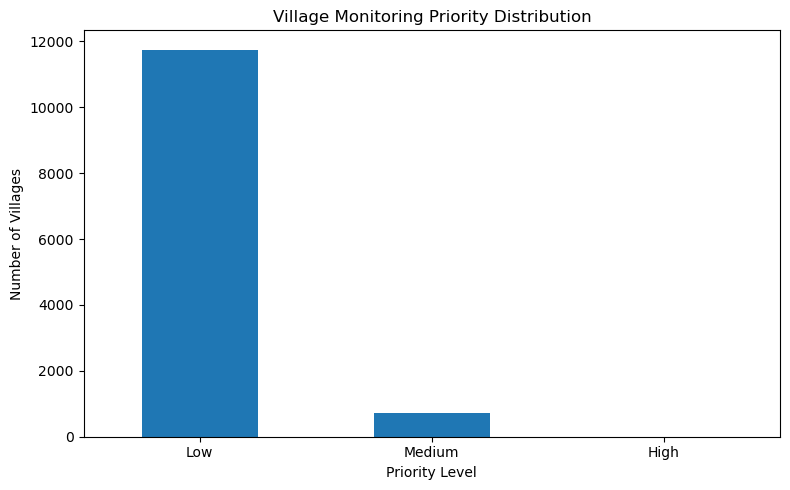

In [50]:
# Priority Level Visualization

import matplotlib.pyplot as plt

priority_counts = priority_data["priority_level"].value_counts().reindex(
    ["Low", "Medium", "High"]
)

plt.figure(figsize=(8, 5))

priority_counts.plot(kind="bar")

plt.xlabel("Priority Level")
plt.ylabel("Number of Villages")
plt.title("Village Monitoring Priority Distribution")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

District-wise Priority Distribution:


priority_level,Low,Medium,High
District,,,
ANGUL,172,4,0
BALASORE,266,3,0
BARGARH,194,0,0
BHADRAKH,10,0,0
BOLANGIR,182,3,0
BOUDH,178,1,0
CUTTACKK,87,0,0
DEOGARH,257,13,0
DHENKANAL,116,36,0


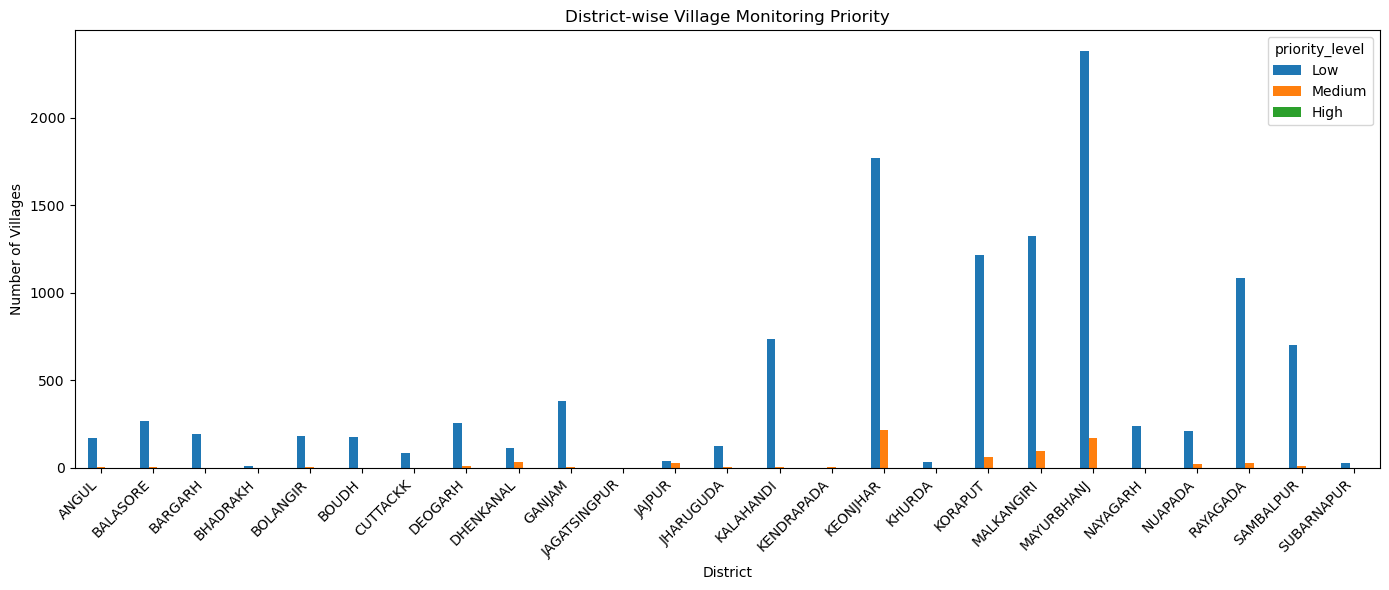

In [51]:
# District-wise Priority Analysis

district_priority = (
    priority_data
    .groupby(["District", "priority_level"], observed=False)
    .size()
    .unstack(fill_value=0)
)

district_priority = district_priority.reindex(
    columns=["Low", "Medium", "High"],
    fill_value=0
)

print("District-wise Priority Distribution:")
display(district_priority)

# Plot
district_priority.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.xlabel("District")
plt.ylabel("Number of Villages")
plt.title("District-wise Village Monitoring Priority")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [52]:
# Save final feature-engineered dataset

feature_output_path = "../data/cleaned/Odisha_FRA_Feature_Engineered.csv"

priority_data.to_csv(
    feature_output_path,
    index=False
)

print("Feature-engineered dataset saved successfully.")
print("File:", feature_output_path)
print("Rows saved:", len(priority_data))
print("Columns saved:", len(priority_data.columns))

print("\nFinal columns:")
print(priority_data.columns.tolist())

Feature-engineered dataset saved successfully.
File: ../data/cleaned/Odisha_FRA_Feature_Engineered.csv
Rows saved: 12460
Columns saved: 19

Final columns:
['District', 'Block', 'Gram Panchayat', 'Village', 'Beneficiary_Count', 'village_key', 'geo_key', 'beneficiary_conflict', 'beneficiary_log', 'block_village_count', 'gp_village_count', 'district_village_count', 'beneficiary_per_gp_village', 'conflict_flag', 'beneficiary_score', 'beneficiary_density_score', 'conflict_score', 'priority_score', 'priority_level']


In [53]:
# K-Means Clustering for Village Monitoring

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select numerical features for clustering
cluster_features = [
    "Beneficiary_Count",
    "beneficiary_log",
    "block_village_count",
    "gp_village_count",
    "district_village_count",
    "beneficiary_per_gp_village",
    "conflict_flag"
]

X = priority_data[cluster_features].copy()

# Handle any missing/infinite values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(0)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

priority_data["cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("\nCluster distribution:")
print(priority_data["cluster"].value_counts().sort_index())

print("\nCluster centers:")
print(kmeans.cluster_centers_)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

K-Means clustering completed.

Cluster distribution:
cluster
0    9002
1    3388
2      70
Name: count, dtype: int64

Cluster centers:
[[-0.43286709 -0.45137925 -0.03969723  0.04299809 -0.07912278 -0.23570987
  -0.0751646 ]
 [ 1.1452448   1.19570243  0.11107422 -0.1156437   0.18038701  0.62632634
  -0.0751646 ]
 [-0.14639594 -0.22463228 -0.30754429  0.10612815  1.38143409 -0.21125732
  13.3041347 ]]


In [54]:
# Analyze K-Means clusters

cluster_summary = priority_data.groupby("cluster").agg(
    villages=("Village", "count"),
    avg_beneficiary=("Beneficiary_Count", "mean"),
    avg_priority_score=("priority_score", "mean"),
    conflict_villages=("conflict_flag", "sum")
).reset_index()

print("K-Means Cluster Summary:")
display(cluster_summary)

K-Means Cluster Summary:


,cluster,villages,avg_beneficiary,avg_priority_score,conflict_villages
0,0,9002,9.761942,15.744918,0
1,1,3388,54.568182,29.905248,0
2,2,70,17.842857,37.619031,70


In [55]:
# Assign interpretable priority category based on K-Means clusters

cluster_priority_map = {
    0: "Low",
    1: "Medium",
    2: "High"
}

priority_data["ml_priority_level"] = (
    priority_data["cluster"]
    .map(cluster_priority_map)
)

print("ML Priority Assignment:")
print(priority_data["ml_priority_level"].value_counts())

print("\nML Priority Summary:")
display(
    priority_data.groupby("ml_priority_level").agg(
        villages=("Village", "count"),
        avg_beneficiary=("Beneficiary_Count", "mean"),
        avg_priority_score=("priority_score", "mean"),
        conflict_villages=("conflict_flag", "sum")
    ).reindex(["Low", "Medium", "High"])
)

ML Priority Assignment:
ml_priority_level
Low       9002
Medium    3388
High        70
Name: count, dtype: int64

ML Priority Summary:


,villages,avg_beneficiary,avg_priority_score,conflict_villages
ml_priority_level,,,,
Low,9002,9.761942,15.744918,0
Medium,3388,54.568182,29.905248,0
High,70,17.842857,37.619031,70


In [56]:
# Add ML priority result to final dataset

final_ml_dataset = priority_data.copy()

print("Final ML dataset:")
print("Rows:", len(final_ml_dataset))
print("Columns:", len(final_ml_dataset.columns))

print("\nFinal columns:")
print(final_ml_dataset.columns.tolist())

display(
    final_ml_dataset[
        [
            "District",
            "Block",
            "Gram Panchayat",
            "Village",
            "Beneficiary_Count",
            "conflict_flag",
            "priority_score",
            "priority_level",
            "cluster",
            "ml_priority_level"
        ]
    ].head(10)
)

Final ML dataset:
Rows: 12460
Columns: 21

Final columns:
['District', 'Block', 'Gram Panchayat', 'Village', 'Beneficiary_Count', 'village_key', 'geo_key', 'beneficiary_conflict', 'beneficiary_log', 'block_village_count', 'gp_village_count', 'district_village_count', 'beneficiary_per_gp_village', 'conflict_flag', 'beneficiary_score', 'beneficiary_density_score', 'conflict_score', 'priority_score', 'priority_level', 'cluster', 'ml_priority_level']


,District,Block,Gram Panchayat,Village,Beneficiary_Count,conflict_flag,priority_score,priority_level,cluster,ml_priority_level
0,ANGUL,ANGUL,BADAKANTAKUL,KARABIRA,8,0,16.870847,Low,0,Low
1,ANGUL,ANGUL,JAGANNATHPUR,ASANABAHAL,3,0,10.474906,Low,0,Low
2,ANGUL,ANGUL,JAGANNATHPUR,REJECTED,1,0,5.232525,Low,0,Low
3,ANGUL,ANGUL,JAGANNATHPUR,SALORE,8,0,16.634316,Low,0,Low
4,ANGUL,ANGUL,JAGANNATHPUR,TARAVA,23,0,24.172422,Low,0,Low
5,ANGUL,ANGUL,PURUNAKOTE,BHRUKUNDI,22,0,24.058711,Low,0,Low
6,ANGUL,ANGUL,PURUNAKOTE,GOPALPUR,8,0,16.713159,Low,0,Low
7,ANGUL,ATHAMALLIK,AMBASARMUNDA,AMSARMUNDA,1,0,5.227050,Low,0,Low
8,ANGUL,ATHAMALLIK,AMBASARMUNDA,CHINTAMANIPUR,4,0,12.144185,Low,0,Low
9,ANGUL,ATHAMALLIK,AMBASARMUNDA,DINABANDHUPUR,1,0,5.227050,Low,0,Low


In [57]:
# Save final ML + feature-engineered dataset

final_ml_output_path = "../data/cleaned/Odisha_FRA_Final_ML_Dataset.csv"

final_ml_dataset.to_csv(
    final_ml_output_path,
    index=False
)

print("Final ML dataset saved successfully.")
print("File:", final_ml_output_path)
print("Rows saved:", len(final_ml_dataset))
print("Columns saved:", len(final_ml_dataset.columns))

Final ML dataset saved successfully.
File: ../data/cleaned/Odisha_FRA_Final_ML_Dataset.csv
Rows saved: 12460
Columns saved: 21


In [58]:
# Final ML dataset validation

print("========== FINAL ML DATASET VALIDATION ==========")

print("Rows:", len(final_ml_dataset))
print("Columns:", len(final_ml_dataset.columns))

print("\nMissing values:")
print(final_ml_dataset.isnull().sum().sum())

print("\nDuplicate rows:")
print(final_ml_dataset.duplicated().sum())

print("\nML Priority distribution:")
print(final_ml_dataset["ml_priority_level"].value_counts())

print("\nCluster distribution:")
print(final_ml_dataset["cluster"].value_counts())

print("\nFinal status: READY")

========== FINAL ML DATASET VALIDATION ==========
Rows: 12460
Columns: 21

Missing values:
0

Duplicate rows:
0

ML Priority distribution:
ml_priority_level
Low       9002
Medium    3388
High        70
Name: count, dtype: int64

Cluster distribution:
cluster
0    9002
1    3388
2      70
Name: count, dtype: int64

Final status: READY
